# 03. Проверка статистических гипотез

**Цель.** Проверить, какие различия из EDA устойчивы, а какие могут быть случайностью. Для каждого из них оценить, насколько оно велико.

**Что уже известно из 02.**
- Купившие проводят на товарных страницах больше времени: медиана 1121 сек против 511 сек.
- Новые посетители конвертируются лучше вернувшихся (24.7% против 14.0%), в выходные конверсия чуть выше (17.8% против 14.8%), рядом с праздником в мае ниже (6.2% против 13.3%).
- Конверсия по источникам трафика различается примерно в 4 раза.

Все тесты делаю **только на train** (9864 сессии).

## Как устроена проверка гипотез

*Статистический тест* отвечает на вопрос: "Могла ли разница, которую я вижу, получиться просто из-за случайности, если на самом деле разницы нет?"

Для этого формулируются две гипотезы:
- **H0 (нулевая гипотеза)**: "ничего интересного нет", группы на самом деле не различаются, а видимая разница появилась случайно;
- **H1 (альтернативная)**: различие есть.

**p-value** показывает вероятность увидеть такую же или ещё большую разницу, *если бы H0 была верна*.

**Житейский пример.** Друг утверждает, что его монетка честная. Я подбрасываю её 100 раз, и выпадает 60 орлов. Насколько это странно для честной монетки? p-value отвечает: если монетка честная, результат "60 или больше орлов или 40 или меньше" получался бы примерно в 5.7% случаев (считаю ниже). Маленький p-value говорит "для честной монетки это редкость", а большой говорит "вполне могло случиться случайно".

Чем p-value **не является**: это не "вероятность, что монетка честная", и это не размер эффекта. При огромной выборке даже крошечная, бесполезная для бизнеса разница даст маленький p-value. Поэтому для каждой гипотезы я считаю ещё и **размер эффекта**, то есть насколько велика разница.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep

from src.config import TARGET
from src.data import load_train
from src.plots import BLUE, CLASS_COLORS, CLASS_LABELS, GRAY, INK_2, ORANGE, save_fig, setup_style
from src.stats_tests import bootstrap_median_diff, cramers_v, rank_biserial

setup_style()
train = load_train()

# Пример с монеткой: 60 орлов из 100 бросков
coin = stats.binomtest(60, n=100, p=0.5, alternative="two-sided")
print(f"p-value для 60 орлов из 100 у честной монетки: {coin.pvalue:.3f}")

p-value для 60 орлов из 100 у честной монетки: 0.057


## Уровень значимости и поправка на множественные сравнения

**Уровень значимости α = 0.05** выбираю заранее, до того как смотреть на результаты тестов. Если p-value меньше α, я отвергаю H0 и говорю "разница статистически значима". Значение 0.05 означает: я готов в 5% случаев принять случайность за настоящий эффект, если эффекта на самом деле нет. Это *ложная тревога*.

**Проблема множественных сравнений.** Я проверяю 6 гипотез. Если в каждой шанс ложной тревоги 5%, то шанс хотя бы одной ложной тревоги среди шести уже 26.5% (считаю ниже). Это как купить шесть лотерейных билетов вместо одного: шанс, что "повезёт" хотя бы раз, растёт.

Поэтому я применяю **поправку Холма**. p-value сортируются по возрастанию: самый маленький сравнивается с α/6, следующий с α/5, и так далее. Она строже, чем "просто 0.05", но мягче, чем поправка Бонферрони (сравнивать всё с α/6).

In [2]:
ALPHA = 0.05
N_TESTS = 6
print(f"Вероятность хотя бы одной ложной тревоги среди {N_TESTS} независимых тестов: "
      f"{1 - (1 - ALPHA) ** N_TESTS:.1%}")

results = []  # сюда собираю результаты всех тестов

Вероятность хотя бы одной ложной тревоги среди 6 независимых тестов: 26.5%


## Гипотеза 1. Время на товарных страницах

- **H0:** время на товарных страницах у купивших и не купивших распределено одинаково. Если взять случайного покупателя и случайного не купившего, каждый с равной вероятностью окажется тем, кто провёл больше времени.
- **H1:** распределения различаются.

**Выбор теста.** Самый известный тест для сравнения двух групп называется *t-тест Стьюдента*. Он сравнивает средние и строго опирается на то, что данные распределены примерно нормально (симметричный "колокол"). Сначала проверяю, так ли это.

купили: n=1526, асимметрия=3.08, Шапиро p (сырые)=3.1e-28, Шапиро p (log)=8.4e-15
не купили: n=8338, асимметрия=9.70, Шапиро p (сырые)=6.9e-29, Шапиро p (log)=6.4e-20


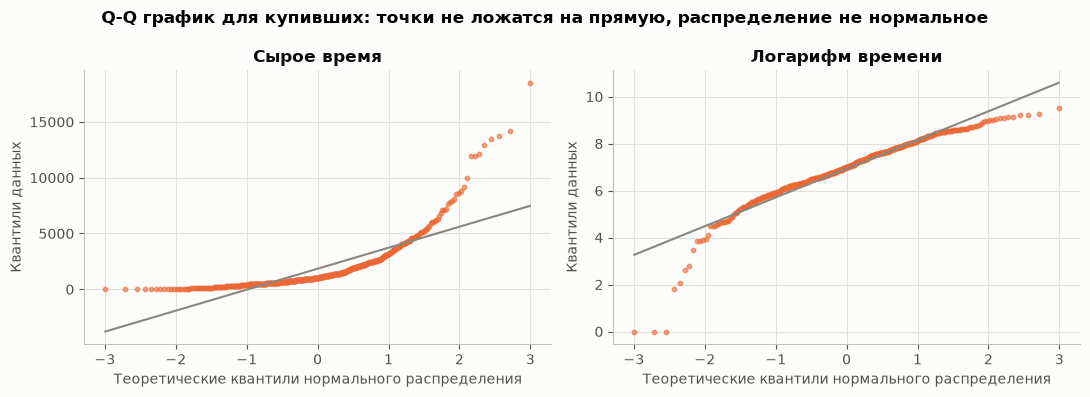

In [3]:
buyers_time = train.loc[train[TARGET] == 1, "ProductRelated_Duration"]
others_time = train.loc[train[TARGET] == 0, "ProductRelated_Duration"]

# Тест Шапиро-Уилка на подвыборке по 500 сессий
# (на тысячах наблюдений он отвергает нормальность даже из-за мелочей)
rng = np.random.default_rng(42)
for name, values in [("купили", buyers_time), ("не купили", others_time)]:
    sample = rng.choice(values, 500, replace=False)
    print(f"{name}: n={len(values)}, асимметрия={stats.skew(values):.2f}, "
          f"Шапиро p (сырые)={stats.shapiro(sample).pvalue:.1e}, "
          f"Шапиро p (log)={stats.shapiro(np.log1p(sample)).pvalue:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, transform, title in [(axes[0], lambda v: v, "Сырое время"),
                             (axes[1], np.log1p, "Логарифм времени")]:
    sample = transform(rng.choice(buyers_time, 500, replace=False))
    (osm, osr), (slope, intercept, _) = stats.probplot(sample, dist="norm")
    ax.scatter(osm, osr, s=10, color=ORANGE, alpha=0.6)
    ax.plot(osm, slope * osm + intercept, color=GRAY, linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("Теоретические квантили нормального распределения")
    ax.set_ylabel("Квантили данных")
fig.suptitle("Q-Q график для купивших: точки не ложатся на прямую, распределение не нормальное",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_qq_product_time")
plt.show()

**Что увидел.** Асимметрия 3.1 у купивших и 9.7 у не купивших (у нормального распределения 0). Тест Шапиро-Уилка отвергает нормальность с p порядка 10⁻²⁸, и даже после логарифма p не больше 10⁻¹⁴. На Q-Q графике точки заметно уходят от прямой. *Q-Q график* сравнивает данные с идеальным нормальным распределением: если бы данные были нормальными, точки легли бы на прямую.

**Что выбираю.** **U-критерий Манна-Уитни.** Он не требует нормальности и сравнивает не средние, а то, насколько часто значения одной группы больше значений другой. Это ровно мой вопрос: "покупатель обычно проводит больше времени?". Среднее же здесь плохо описывает "типичную" сессию: его сильно тянут вверх несколько многочасовых визитов.

Размер эффекта:
- **вероятность превосходства**: с какой вероятностью случайный покупатель провёл на товарных страницах больше времени, чем случайный не купивший (0.5 означает, что разницы нет);
- **разница медиан** в секундах с 95% бутстрэп-интервалом. *Бутстрэп* помогает оценить точность числа: 2000 раз случайно пересобираю выборку из тех же данных и смотрю, насколько меняется результат.

In [4]:
mw = stats.mannwhitneyu(buyers_time, others_time, alternative="two-sided")
prob_superiority, r_rb = rank_biserial(buyers_time, others_time)
med_diff, med_ci = bootstrap_median_diff(buyers_time, others_time)

print(f"U = {mw.statistic:.0f}, p-value = {mw.pvalue:.1e}")
print(f"Вероятность превосходства: {prob_superiority:.3f} (ранговая бисериальная r = {r_rb:.3f})")
print(f"Разница медиан: {med_diff:.0f} сек ({med_diff / 60:.1f} мин), "
      f"95% интервал [{med_ci[0]:.0f}; {med_ci[1]:.0f}] сек")

# Для сравнения: t-тест Уэлча на логарифме (в семейство тестов не включаю, это проверка устойчивости)
welch = stats.ttest_ind(np.log1p(buyers_time), np.log1p(others_time), equal_var=False)
print(f"Для сравнения, t-тест Уэлча на log(1 + время): p-value = {welch.pvalue:.1e}")

results.append({
    "гипотеза": "1. Время на товарных страницах у купивших больше",
    "тест": "Манн-Уитни",
    "p_value": mw.pvalue,
    "размер эффекта": f"P(покупатель дольше) = {prob_superiority:.2f}; медианы +{med_diff / 60:.1f} мин",
})

U = 8591395, p-value = 2.2e-105
Вероятность превосходства: 0.675 (ранговая бисериальная r = 0.350)
Разница медиан: 610 сек (10.2 мин), 95% интервал [517; 677] сек
Для сравнения, t-тест Уэлча на log(1 + время): p-value = 2.5e-166


**Что увидел.** p-value около 10⁻¹⁰⁵, то есть случайностью такую разницу объяснить нельзя. Вероятность превосходства 0.675: в двух случаях из трёх случайный покупатель провёл на товарных страницах больше времени, чем случайный не купивший. Разница медиан 610 секунд (около 10 минут), 95% интервал от 517 до 677 секунд. t-тест Уэлча на логарифме приводит к тому же выводу.

**Что это значит.** Разница статистически значима и **заметная по размеру**: ранговая бисериальная корреляция 0.35 по общепринятой шкале считается средним эффектом. Но это далеко не идеальное разделение: в трети пар "покупатель и не купивший" дольше сидел как раз не купивший. По одному времени предсказать покупку не получится.

## Гипотезы 2-4. Сравнение конверсии в двух группах

Для категориальных признаков ("новый / вернувшийся", "выходной / будний") сравниваю **доли покупок**. Тест: **хи-квадрат** для таблицы сопряжённости 2×2. *Таблица сопряжённости* показывает, сколько сессий в каждой комбинации: новый и купил, новый и не купил и т.д. Тест сравнивает её с тем, какой она была бы, если бы признак не влиял на покупку. Условие применимости: ожидаемое число сессий в каждой клетке не меньше 5. Проверяю его в коде.

Размер эффекта для таких сравнений:
- **разница конверсий** в процентных пунктах (п.п.) с 95% интервалом, самый понятный для бизнеса вариант;
- **относительный риск**: во сколько раз конверсия одной группы выше, чем другой;
- **V Крамера**: универсальная мера силы связи от 0 до 1. По шкале Коэна 0.1 считается слабой связью, 0.3 средней, 0.5 сильной.

In [5]:
def compare_two_groups(df, group_col, group_a, group_b, label_a, label_b):
    """Хи-квадрат 2x2 и размеры эффекта для конверсии группы A против группы B."""
    table = pd.crosstab(df[group_col], df[TARGET]).loc[[group_a, group_b]]
    chi2, p_value, dof, expected = stats.chi2_contingency(table, correction=False)
    buys_a, n_a = table.loc[group_a, 1], table.loc[group_a].sum()
    buys_b, n_b = table.loc[group_b, 1], table.loc[group_b].sum()
    conv_a, conv_b = buys_a / n_a, buys_b / n_b
    ci_low, ci_high = confint_proportions_2indep(buys_a, n_a, buys_b, n_b, method="newcomb")
    print(f"{label_a}: {buys_a}/{n_a} = {conv_a:.1%};  {label_b}: {buys_b}/{n_b} = {conv_b:.1%}")
    print(f"Минимальное ожидаемое число в клетке: {expected.min():.0f}")
    print(f"χ² = {chi2:.1f}, p-value = {p_value:.1e}")
    print(f"Разница: {100 * (conv_a - conv_b):+.1f} п.п., 95% интервал "
          f"[{100 * ci_low:+.1f}; {100 * ci_high:+.1f}] п.п.")
    print(f"Относительный риск: {conv_a / conv_b:.2f};  V Крамера: {cramers_v(table):.3f}")
    return {"p_value": p_value, "diff": conv_a - conv_b, "ci": (ci_low, ci_high),
            "rr": conv_a / conv_b, "v": cramers_v(table)}

### Гипотеза 2. Новые посетители против вернувшихся

- **H0:** у новых и вернувшихся посетителей одинаковая вероятность покупки.
- **H1:** вероятности различаются.

Группу `Other` (74 сессии, непонятно, кто это) в сравнение не включаю.

In [6]:
h2 = compare_two_groups(train, "VisitorType", "New_Visitor", "Returning_Visitor", "новые", "вернувшиеся")
results.append({
    "гипотеза": "2. Новые посетители покупают чаще вернувшихся",
    "тест": "хи-квадрат 2×2", "p_value": h2["p_value"],
    "размер эффекта": f"{100 * h2['diff']:+.1f} п.п.; в {h2['rr']:.2f} раза; V = {h2['v']:.2f}",
})

новые: 333/1347 = 24.7%;  вернувшиеся: 1180/8443 = 14.0%
Минимальное ожидаемое число в клетке: 208
χ² = 102.7, p-value = 4.0e-24
Разница: +10.7 п.п., 95% интервал [+8.4; +13.2] п.п.
Относительный риск: 1.77;  V Крамера: 0.102


**Что увидел.** Новые: 24.7%, вернувшиеся: 14.0%. Разница +10.7 п.п. (95% интервал от +8.4 до +13.2), то есть новые покупают в 1.77 раза чаще. p-value около 10⁻²⁴. V Крамера 0.10.

**Что это значит.** Разница статистически значима, и для бизнеса она большая: плюс 77% к конверсии. А V Крамера при этом "слабый". Противоречия тут нет. V измеряет, насколько хорошо по типу посетителя *можно предсказать* покупку для конкретной сессии. Даже среди новых три четверти не покупают, поэтому предсказание по одному этому признаку плохое, хотя средние конверсии групп заметно отличаются.

### Гипотеза 3. Выходные против будних

- **H0:** в выходные и будни одинаковая вероятность покупки.
- **H1:** вероятности различаются.

In [7]:
h3 = compare_two_groups(train, "Weekend", 1, 0, "выходные", "будни")
results.append({
    "гипотеза": "3. В выходные конверсия выше",
    "тест": "хи-квадрат 2×2", "p_value": h3["p_value"],
    "размер эффекта": f"{100 * h3['diff']:+.1f} п.п.; в {h3['rr']:.2f} раза; V = {h3['v']:.2f}",
})

выходные: 406/2286 = 17.8%;  будни: 1120/7578 = 14.8%
Минимальное ожидаемое число в клетке: 354
χ² = 11.9, p-value = 5.5e-04
Разница: +3.0 п.п., 95% интервал [+1.3; +4.8] п.п.
Относительный риск: 1.20;  V Крамера: 0.035


**Что увидел.** Выходные: 17.8%, будни: 14.8%. Разница +3.0 п.п. (95% интервал от +1.3 до +4.8), в 1.20 раза. p-value = 5.5·10⁻⁴. V Крамера 0.035.

**Что это значит.** Разница статистически значима, но небольшая. Нижняя граница интервала всего +1.3 п.п. Для модели это слабый признак. Для бизнеса это, возможно, повод запускать акции в выходные, но только после A/B-теста.

### Гипотеза 4. Близость праздника (внутри мая)

- **H0:** в мае конверсия в дни рядом с праздником (`SpecialDay > 0`) такая же, как в остальные дни мая.
- **H1:** конверсия различается.

Сравниваю только внутри мая. Так я убираю влияние месяца: в 02 выяснилось, что `SpecialDay > 0` бывает только в феврале и мае, а февраль почти без покупок в любые дни.

In [8]:
may = train[train["Month"] == "May"].assign(special_day_flag=lambda d: (d["SpecialDay"] > 0).astype(int))
h4 = compare_two_groups(may, "special_day_flag", 1, 0, "рядом праздник", "обычные дни мая")
results.append({
    "гипотеза": "4. Рядом с праздником (в мае) конверсия ниже",
    "тест": "хи-квадрат 2×2", "p_value": h4["p_value"],
    "размер эффекта": f"{100 * h4['diff']:+.1f} п.п.; в {h4['rr']:.2f} раза; V = {h4['v']:.2f}",
})

рядом праздник: 59/951 = 6.2%;  обычные дни мая: 233/1752 = 13.3%
Минимальное ожидаемое число в клетке: 103
χ² = 32.2, p-value = 1.4e-08
Разница: -7.1 п.п., 95% интервал [-9.3; -4.8] п.п.
Относительный риск: 0.47;  V Крамера: 0.109


**Что увидел.** Рядом с праздником: 6.2%, в обычные дни мая: 13.3%. Разница -7.1 п.п. (95% интервал от -9.3 до -4.8), то есть конверсия в 2.1 раза ниже (относительный риск 0.47). p-value около 10⁻⁸.

**Что это значит.** Эффект значим и большой по величине. Но доказательная база узкая: по сути это один праздник в одном году (День матери). Признак `SpecialDay` к тому же построен авторами по своей формуле, и что именно в нём учтено, не до конца ясно. Выводы про "праздники вообще" я бы не делал.

## Гипотеза 5. Источник трафика

- **H0:** конверсия одинакова для всех источников трафика.
- **H1:** хотя бы один источник отличается.

Тест: хи-квадрат для таблицы "источник × покупка". Источники, у которых меньше 100 сессий, объединяю в "другие", как в 02, чтобы в каждой клетке хватало ожидаемых наблюдений.

In [9]:
traffic_counts = train["TrafficType"].value_counts()
big_sources = traffic_counts[traffic_counts >= 100].index
traffic_group = np.where(train["TrafficType"].isin(big_sources), train["TrafficType"].astype(str), "другие")
traffic_table = pd.crosstab(traffic_group, train[TARGET])
chi2, p_traffic, dof, expected = stats.chi2_contingency(traffic_table)
v_traffic = cramers_v(traffic_table)
conv_by_source = traffic_table[1] / traffic_table.sum(axis=1)
print(f"Групп источников: {len(traffic_table)}, степеней свободы: {dof}")
print(f"Минимальное ожидаемое число в клетке: {expected.min():.0f}")
print(f"χ² = {chi2:.1f}, p-value = {p_traffic:.1e}, V Крамера = {v_traffic:.3f}")
print(f"Конверсия по группам: от {conv_by_source.min():.1%} до {conv_by_source.max():.1%}")
results.append({
    "гипотеза": "5. Конверсия зависит от источника трафика",
    "тест": "хи-квадрат 12×2", "p_value": p_traffic,
    "размер эффекта": f"V = {v_traffic:.2f}; от {conv_by_source.min():.1%} до {conv_by_source.max():.1%}",
})

Групп источников: 12, степеней свободы: 11
Минимальное ожидаемое число в клетке: 22
χ² = 304.3, p-value = 1.1e-58, V Крамера = 0.176
Конверсия по группам: от 6.4% до 27.6%


**Что увидел.** χ² = 304, p-value около 10⁻⁵⁸, V Крамера 0.18, это самая сильная связь среди категориальных признаков. Конверсия по группам источников от 6.4% до 27.6%.

**Что это значит.** Источник трафика оказался значимым и самым сильным категориальным признаком. Тест говорит только, что "источники различаются", но не говорит, какие именно. Для этого нужны попарные сравнения с ещё одной поправкой. Делать их не стал: без расшифровки кодов бизнес-ценность таких сравнений невелика.

## Гипотеза 6 (контрольная). Регион

Эту гипотезу я добавил уже здесь. В 02 я не смотрел на регионы подробно, но по таблицам разброс конверсии небольшой. Хотел проверить, что тест не находит "значимость" везде, где я её ищу. Заодно это практичный вопрос: можно ли настраивать промо по регионам?

- **H0:** конверсия одинакова во всех регионах.
- **H1:** хотя бы один регион отличается.

In [10]:
region_table = pd.crosstab(train["Region"], train[TARGET])
chi2_r, p_region, dof_r, expected_r = stats.chi2_contingency(region_table)
v_region = cramers_v(region_table)
conv_by_region = region_table[1] / region_table.sum(axis=1)
print(f"Регионов: {len(region_table)}, минимальное ожидаемое число в клетке: {expected_r.min():.0f}")
print(f"χ² = {chi2_r:.1f}, p-value = {p_region:.3f}, V Крамера = {v_region:.3f}")
print(f"Конверсия по регионам: от {conv_by_region.min():.1%} до {conv_by_region.max():.1%}")
results.append({
    "гипотеза": "6. Конверсия зависит от региона (контроль)",
    "тест": "хи-квадрат 9×2", "p_value": p_region,
    "размер эффекта": f"V = {v_region:.2f}; от {conv_by_region.min():.1%} до {conv_by_region.max():.1%}",
})

Регионов: 9, минимальное ожидаемое число в клетке: 42
χ² = 5.7, p-value = 0.682, V Крамера = 0.024
Конверсия по регионам: от 14.2% до 17.0%


**Что увидел.** p-value = 0.682, V Крамера 0.024. Конверсия по регионам от 14.2% до 17.0%.

**Что это значит.** Отвергнуть H0 нельзя: разброс между регионами вполне объясняется случайностью. Важно: это не доказывает, что регионы "одинаковые". Это значит, что данных не хватает, чтобы заметить разницу, если она и есть. Но если разница и есть, она маленькая. Настраивать промо по регионам, судя по этим данным, смысла мало.

## Сводная таблица с поправкой Холма

In [11]:
summary = pd.DataFrame(results)
reject, p_holm, _, _ = multipletests(summary["p_value"], alpha=ALPHA, method="holm")
summary["p (Холм)"] = p_holm
summary["значимо при α=0.05"] = np.where(reject, "да", "нет")
summary["p_value"] = summary["p_value"].map(lambda p: f"{p:.1e}")
summary["p (Холм)"] = summary["p (Холм)"].map(lambda p: f"{p:.1e}" if p < 0.001 else f"{p:.3f}")
summary.set_index("гипотеза")

,тест,p_value,размер эффекта,p (Холм),значимо при α=0.05
гипотеза,,,,,
1. Время на товарных страницах у купивших больше,Манн-Уитни,2.2e-105,P(покупатель дольше) = 0.68; медианы +10.2 мин,1.3e-104,да
2. Новые посетители покупают чаще вернувшихся,хи-квадрат 2×2,4.0e-24,+10.7 п.п.; в 1.77 раза; V = 0.10,1.6e-23,да
3. В выходные конверсия выше,хи-квадрат 2×2,5.5e-04,+3.0 п.п.; в 1.20 раза; V = 0.03,0.001,да
4. Рядом с праздником (в мае) конверсия ниже,хи-квадрат 2×2,1.4e-08,-7.1 п.п.; в 0.47 раза; V = 0.11,4.2e-08,да
5. Конверсия зависит от источника трафика,хи-квадрат 12×2,1.1e-58,V = 0.18; от 6.4% до 27.6%,5.4e-58,да
6. Конверсия зависит от региона (контроль),хи-квадрат 9×2,6.8e-01,V = 0.02; от 14.2% до 17.0%,0.682,нет


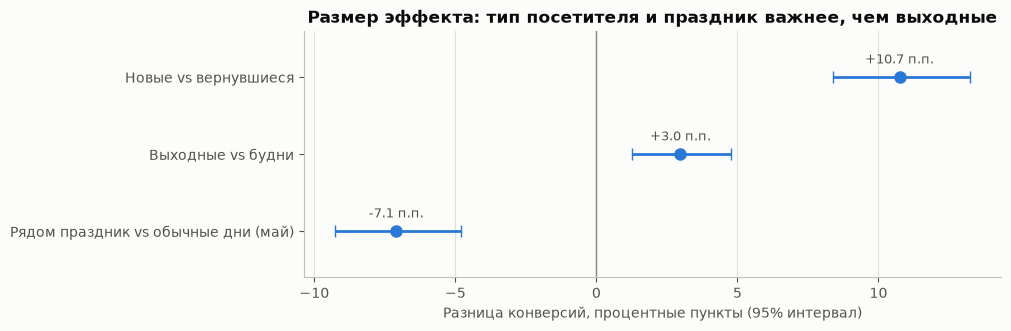

In [12]:
# Разница конверсий с интервалами для гипотез 2-4: на одном графике видно и знак, и величину
effects = pd.DataFrame({
    "label": ["Новые vs вернувшиеся", "Выходные vs будни", "Рядом праздник vs обычные дни (май)"],
    "diff": [h2["diff"], h3["diff"], h4["diff"]],
    "low": [h2["ci"][0], h3["ci"][0], h4["ci"][0]],
    "high": [h2["ci"][1], h3["ci"][1], h4["ci"][1]],
})
fig, ax = plt.subplots(figsize=(9, 3.2))
y_pos = np.arange(len(effects))[::-1]
ax.errorbar(100 * effects["diff"], y_pos,
            xerr=[100 * (effects["diff"] - effects["low"]), 100 * (effects["high"] - effects["diff"])],
            fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=4, markersize=8)
for yp, d in zip(y_pos, effects["diff"]):
    ax.text(100 * d, yp + 0.18, f"{100 * d:+.1f} п.п.", ha="center", color=INK_2, fontsize=9)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(effects["label"])
ax.set_ylim(-0.6, len(effects) - 0.4)
ax.set_xlabel("Разница конверсий, процентные пункты (95% интервал)")
ax.set_title("Размер эффекта: тип посетителя и праздник важнее, чем выходные")
ax.grid(axis="y", visible=False)
save_fig(fig, "03_effect_sizes")
plt.show()

**Что увидел.** После поправки Холма значимыми остаются гипотезы 1-5, а гипотеза 6 (регион) нет. Самые маленькие p-value у времени на товарных страницах и источника трафика. Если смотреть на размер эффекта в процентных пунктах, крупнее всего тип посетителя (+10.7 п.п.) и праздник (-7.1 п.п.), а выходные дают всего +3.0 п.п.

**Что это значит.** Поправка ничего не поменяла: p-value первых пяти гипотез настолько малы, что прошли бы и самую строгую проверку. Важнее другое: величина эффектов разная. "Значимо" у выходных и у типа посетителя, но по силе они отличаются в три с лишним раза.

## Значимость ≠ причинность

Все тесты выше отвечают на вопрос "связаны ли признак и покупка", но **не** на вопрос "вызывает ли признак покупку". Это наблюдательные данные: никто не назначал посетителям случайно, сколько времени провести на сайте или в какой день прийти.

- **Время на товарных страницах.** Скорее всего, причинность во многом обратная: человек, который *уже решил* купить, выбирает размер, сравнивает характеристики, оформляет заказ, и поэтому проводит на сайте больше времени. Если удлинить людям визиты (например, усложнить навигацию), покупать чаще они не станут.
- **Новые посетители.** Возможно, новых приводит реклама конкретного товара, и они приходят с готовым намерением. Тогда дело не в "новизне", а в источнике и цели визита. Проверить это без данных о кампаниях нельзя.
- **Праздники.** Перед праздником может меняться состав аудитории (больше людей, которые "просто смотрят идеи"). Конверсия падает из-за смены аудитории, а не потому, что праздник "мешает" покупать.

Единственный надёжный способ проверить причинность это эксперимент (A/B-тест): случайно разделить посетителей на группы и изменить что-то только в одной из них. Об этом в ноутбуке 07.

## Итоги

- **Время на товарных страницах:** у купивших медиана больше на 610 секунд (≈10 минут), вероятность превосходства 0.675, p ≈ 10⁻¹⁰⁵. Эффект средний по силе, но далеко не идеальный разделитель.
- **Новые посетители** конвертируются лучше вернувшихся: +10.7 п.п. (24.7% против 14.0%), в 1.77 раза. Статистически значимо.
- **Рядом с праздником** (в мае) конверсия ниже на 7.1 п.п. (6.2% против 13.3%). Значимо, но это по сути один праздник.
- **Выходные:** +3.0 п.п., значимо, но эффект небольшой. **Источник трафика:** значимо, V Крамера 0.18, самая сильная связь среди категориальных признаков.
- **Регион:** разница не значима (p = 0.682). После поправки Холма значимы 5 гипотез из 6.

## Что не получилось или удивило

- Все пять "содержательных" гипотез оказались значимыми, и даже очень. При 9864 сессиях тест замечает и небольшие различия. Поэтому полезнее смотреть на размер эффекта, а не на сам факт значимости.
- V Крамера "слабый" у признака, который увеличивает конверсию на 77%. Пришлось разобраться, что V измеряет предсказательную силу для отдельной сессии, а не разницу средних.

## Новые идеи

- Поскольку время на страницах может быть следствием покупки, в 04 стоит отдельно подумать, какие признаки "знают" о покупке (не только `PageValues`, но и показатели выхода, и длительности).
- Тип посетителя и источник трафика могут быть связаны между собой (новых приводит реклама). При большем времени проверил бы это таблицей "тип × источник".

## Следующие шаги

- **В ноутбуке 04** займусь новыми признаками, проверкой их пользы на кросс-валидации и разбором утечки через `PageValues`.
- **При большем времени:** попарные сравнения источников трафика с поправкой, анализ "тип посетителя × источник".